# KPMP CKD: non-H&E stain overview

View **PAS, trichrome (`TRI`) and silver (`SIL`) WSIs from five CKD-enrolled participants** in the [frozen KPMP roster](../manifests/kpmp_ckd_demo.csv). These are different slides matched by participant; a shared biopsy, serial-section relationship or spatial registration is not established. H&E remains available in the roster as a separate reference.

The previews retain source RGB colour and the complete slide extent, using bounded pyramid reads and thumbnail reduction. Preprocessing is a scientific choice: grayscale conversion, stain separation, normalization or artefact rules need a purpose and validation appropriate to the stain and tissue. This overview applies thumbnail reduction only.

In [1]:
from pathlib import Path
import csv
import json
import os
import subprocess
import sys
import tempfile

for key in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[key] = '1'

from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT = None  # Set Path(...) when launching outside this checkout.
if PROJECT is None:
    PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'pyproject.toml').is_file() and (p / 'src/wsi_preprocessing/inspection.py').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Open from this checkout or set PROJECT explicitly.')
PROJECT = Path(PROJECT).resolve(strict=True)
sys.path.insert(0, str(PROJECT))
from src.wsi_preprocessing.inspection import read_thumbnail

OUTPUT_ROOT = None  # Default: ignored outputs/kpmp_stain_overview/ in this project.
output_root = Path(OUTPUT_ROOT or PROJECT / 'outputs/kpmp_stain_overview')
output_root.mkdir(parents=True, exist_ok=True)
RUN = Path(tempfile.mkdtemp(prefix='overview_', dir=output_root))
with (PROJECT / 'manifests/kpmp_ckd_demo.csv').open(newline='') as stream:
    roster = list(csv.DictReader(stream))
all_present = all((PROJECT / row['path']).is_file() for row in roster)
command = [sys.executable, str(PROJECT / 'scripts/download_kpmp.py'), '--workers', '2', '--max-gb', '5']
if all_present:
    command.append('--verify-only')
with (RUN / 'acquisition.log').open('x') as log:
    acquired = subprocess.run(command, cwd=PROJECT, stdout=log, stderr=subprocess.STDOUT, timeout=1800)
if acquired.returncode:
    raise RuntimeError(f'KPMP acquisition or verification failed; inspect {RUN / "acquisition.log"}')

STAINS = ('PAS', 'TRI', 'SIL')
selected = [row for row in roster if row['stain'] in STAINS]
patients = list(dict.fromkeys(row['case_id'] for row in selected))
assert len(selected) == 15 and len(patients) == 5
assert {(r['case_id'], r['stain']) for r in selected} == {(p, s) for p in patients for s in STAINS}
THUMBNAIL_EDGE = 768
MAX_READ_PIXELS = 12_000_000  # Per slide; at most 15 bounded reads in this overview.
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

Matplotlib is building the font cache; this may take a moment.


## Slide metadata

Native dimensions and MPP below come from recorded scanner metadata. MPP is not independently calibrated here; missing values remain unavailable. Participant and file identifiers retain the roster mapping.

In [2]:
thumbnails, records, read_metadata = {}, [], []
for row in selected:
    rgb, metadata = read_thumbnail(PROJECT / row['path'], max_size=THUMBNAIL_EDGE,
                                   max_read_pixels=MAX_READ_PIXELS,
                                   max_total_read_pixels=MAX_READ_PIXELS)
    thumbnails[row['case_id'], row['stain']] = rgb
    width, height = metadata['dimensions']
    mpp = metadata.get('mpp')
    records.append({'Patient': row['case_id'], 'Stain': row['stain'], 'File ID': row['file_id'],
                    'Native dimensions (px)': f'{width} × {height}',
                    'Native MPP x/y (µm/px)': 'unavailable' if mpp is None else f'{mpp[0]:.6f} / {mpp[1]:.6f}'})
    read_metadata.append({'patient': row['case_id'], 'stain': row['stain'], 'file_id': row['file_id'],
                          'source': row['path'], 'recorded_sha256': row['sha256'],
                          'read_level': metadata['read_level'], 'read_dimensions': metadata['read_dimensions'],
                          'read_strategy': metadata.get('read_strategy'),
                          'thumbnail_dimensions': metadata['thumbnail_dimensions'],
                          'native_dimensions': metadata['dimensions'], 'native_mpp': mpp,
                          'mpp_source': metadata.get('mpp_source')})
metadata_table = pd.DataFrame(records)
metadata_table.to_csv(RUN / 'slide_metadata.csv', index=False)
(RUN / 'overview_metadata.json').write_text(json.dumps({
    'acquisition_mode': 'verify-only' if all_present else 'download-missing',
    'slides_displayed': 15, 'thumbnail_edge': THUMBNAIL_EDGE,
    'max_source_pixels_per_slide': MAX_READ_PIXELS, 'slides': read_metadata}, indent=2) + '\n')
display(metadata_table.set_index(['Patient', 'Stain']))

File ID Native dimensions (px)  \
Patient  Stain                                                                
31-10081 PAS    d41d2dcc-548c-42e0-b93a-28504c9c7847          73740 × 55956   
         TRI    cf83790b-37ed-45b1-9426-1555b4a477e2          75733 × 53976   
         SIL    c251cc03-b1ed-4688-b30d-253dae319f7d          75733 × 53811   
31-10154 PAS    9756c31e-9651-414a-a426-9dec18dc60b7         111607 × 41957   
         TRI    a8442163-05c9-497b-8974-e493e2c8b5de          99649 × 45908   
         SIL    c60a98a9-deeb-46ca-9b0e-ef971c8336c9         109614 × 49717   
29-10819 PAS    4c015d1b-0372-4bf7-9934-a3611b892e79         135523 × 35375   
         TRI    96aedfcf-9362-4360-9ddf-0f65d6e47865         141502 × 53051   
         SIL    250697bf-42ca-4506-b19e-0582fbe00c4f         101642 × 51029   
27-10365 PAS    457f802e-7738-48a2-9ef4-caeb88b551e0          95663 × 45408   
         TRI    38583cee-eecc-40de-95f8-f09225fc9fd6          93670 × 48544   
         SIL    eb452b87-7f62-4fbc-aa31-307068758fac          81712 × 55964   
28-12781 PAS    96cf672b-0f98-4629-97f0-ac5f84d631f3          62739 × 42574   
         TRI    fdbdea61-dd80-4d46-9d2f-0400d1d58353          61341 × 37983   
         SIL    7e9bd113-6389-4991-bb32-1d7a5fcf94d8          75733 × 53646   

               Native MPP x/y (µm/px)  
Patient  Stain                         
31-10081 PAS      0.252700 / 0.252700  
         TRI      0.252700 / 0.252700  
         SIL      0.252700 / 0.252700  
31-10154 PAS      0.252700 / 0.252700  
         TRI      0.252700 / 0.252700  
         SIL      0.252700 / 0.252700  
29-10819 PAS      0.252700 / 0.252700  
         TRI      0.252700 / 0.252700  
         SIL      0.252700 / 0.252700  
27-10365 PAS      0.252700 / 0.252700  
         TRI      0.252700 / 0.252700  
         SIL      0.252700 / 0.252700  
28-12781 PAS      0.262761 / 0.262761  
         TRI      0.262761 / 0.262761  
         SIL      0.252700 / 0.252700

## PAS, trichrome and silver

Rows group participants; columns group stains. Every complete-slide thumbnail is fitted independently while preserving its aspect ratio. **Panels are not registered and do not share a physical scale.** Differences in apparent tissue size or position should not be interpreted as differences at matched anatomical locations.

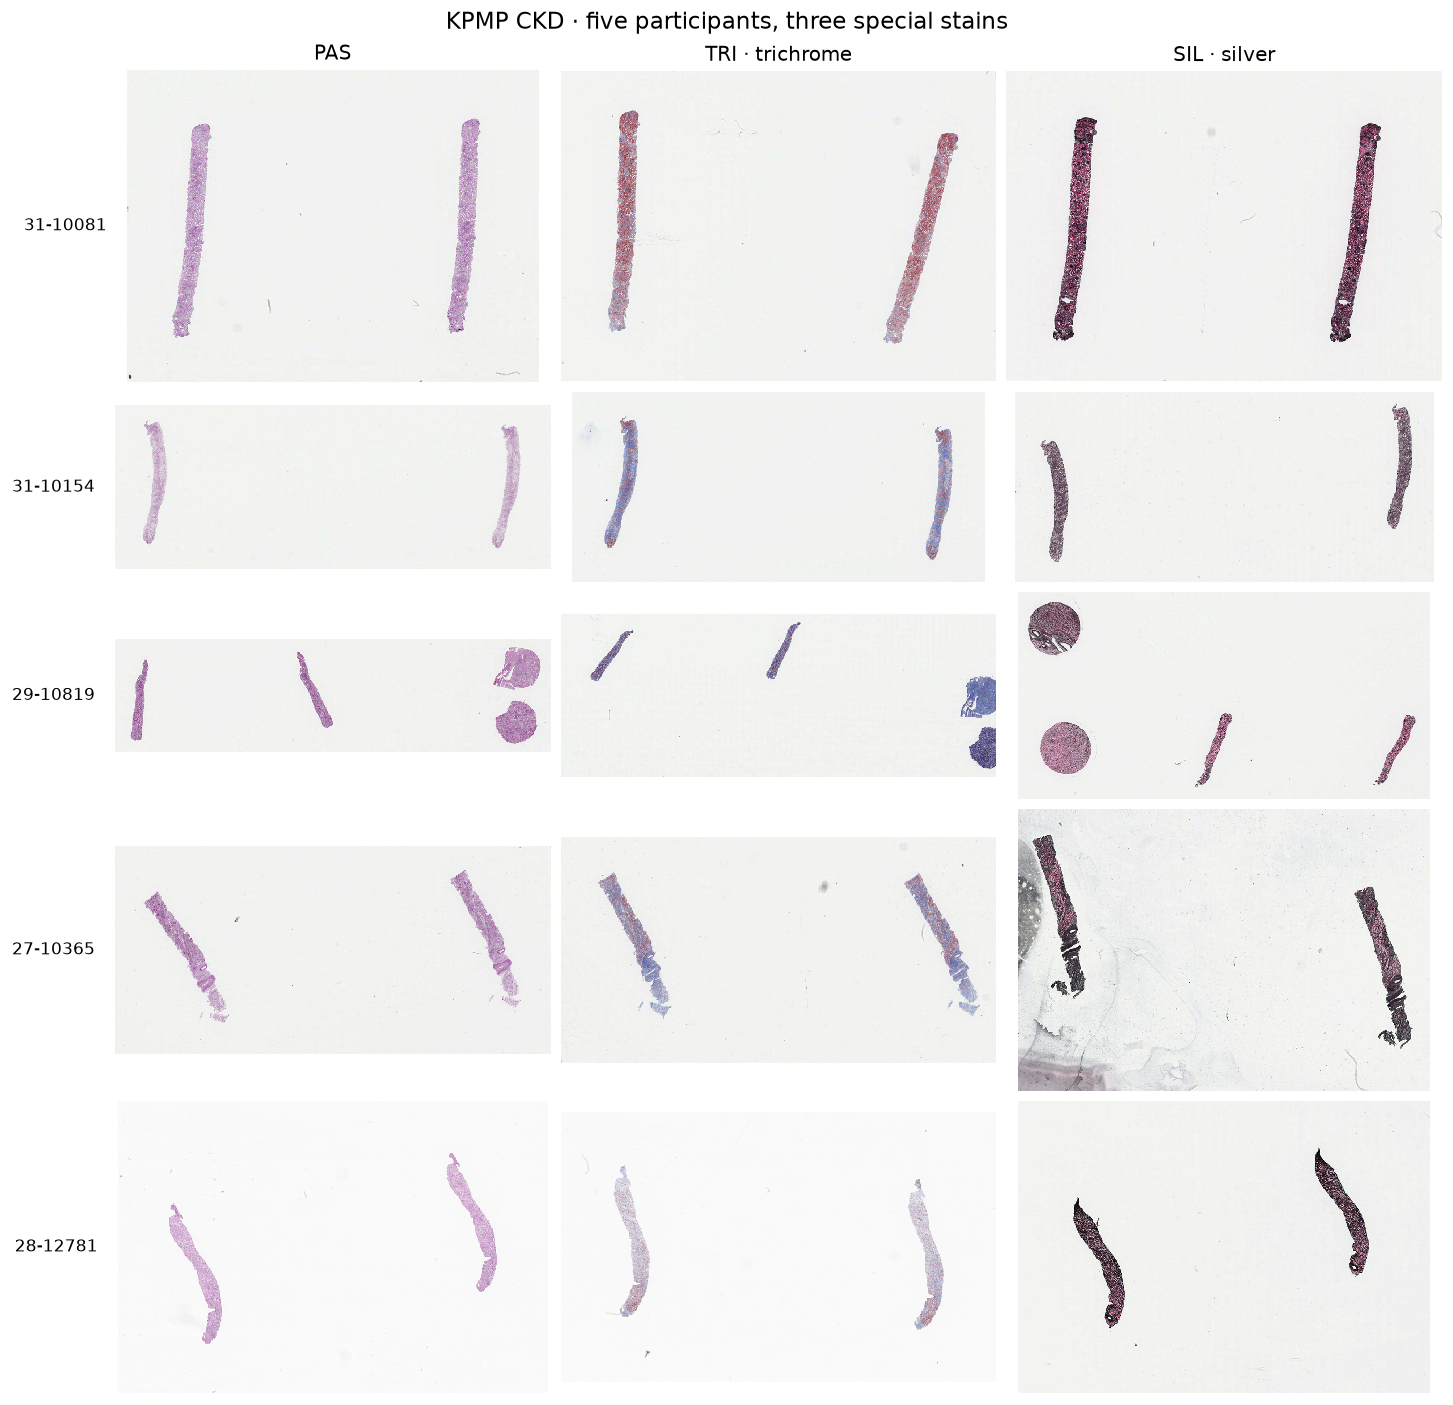

In [3]:
row_heights = [max(thumbnails[p, stain].shape[0] / thumbnails[p, stain].shape[1]
                   for stain in STAINS) for p in patients]
fig, axes = plt.subplots(5, 3, figsize=(12, 11.6), layout='constrained',
                         gridspec_kw={'height_ratios': row_heights})
column_titles = {'PAS': 'PAS', 'TRI': 'TRI · trichrome', 'SIL': 'SIL · silver'}
for row_index, patient in enumerate(patients):
    for column, stain in enumerate(STAINS):
        ax = axes[row_index, column]
        ax.imshow(thumbnails[patient, stain], interpolation='nearest')
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row_index == 0:
            ax.set_title(column_titles[stain], fontsize=12)
        if column == 0:
            ax.set_ylabel(patient, rotation=0, ha='right', va='center', labelpad=12)
fig.suptitle('KPMP CKD · five participants, three special stains', fontsize=14)
fig.savefig(RUN / 'kpmp_special_stains.png')
plt.show()

**Reference spots and silver-stain background.** Note the round reference spots in **29-10819**, especially the **SIL** panel; their specific control identity is not recorded in the roster. Distinguish them from the elongated biopsy cores when defining analysis regions. The **27-10365 SIL** slide also shows conspicuous grey/dark material consistent with background contamination outside the cores. Inspect that background separately from tissue-bound silver staining rather than applying a blanket dark-pixel exclusion.

## Brightfield stains are not independent marker channels

An RGB brightfield scan records transmitted red, green and blue light. Each dye can affect several RGB bands, so splitting RGB or converting it to grayscale does not isolate a particular stain. Grayscale can support morphology or segmentation when validated; it is not a stain-specific measurement. Fluorescence commonly acquires separate emission-band images that can be displayed with arbitrary colours, subject to spectral overlap and acquisition limitations. These RGB scans are not already-separated fluorescence marker channels. [QuPath image concepts](https://qupath.readthedocs.io/en/stable/docs/concepts/images.html#color-deconvolution)

Brightfield colour deconvolution instead estimates stain contributions in optical-density space, $\mathrm{OD}=-\log_{10}(I/I_0)$, using background intensity $I_0$ and protocol-specific stain vectors. It is a model, not a direct concentration measurement. An H&E matrix is not a PAS/trichrome/silver matrix: trichrome mixtures can exceed simple three-dye assumptions, while silver deposits can scatter light and make absorption-only unmixing unreliable. Estimated stain maps therefore need validation for their intended use. [Landini: Colour Deconvolution 2](https://blog.bham.ac.uk/intellimic/g-landini-software/colour-deconvolution-2/)

Data: [Kidney Precision Medicine Project](https://www.kpmp.org/) · [KPMP citation guidance](https://www.kpmp.org/help-docs/citing-kpmp-data) · [Local dataset provenance](../docs/datasets.md#kpmp-ckd).